In [1]:
from dataml.ml_model import MLModel
from dataml.model.lightgbm_model import LightGBMModel
from dataml.model.logistic_regression_model import LogisticRegressionModel
from dataml.feature_explain import ShapFeatureExplain
import os

from dataml.datasets import (
    SQLDataset,
    DefaultWarehouse,
    LocalDataset
)

from dataml.feature_process import (
    FeatureProcess,
    MissValueFeatureProcess,
    MostValueValueFeatureProcess,
    VarDerivaticeFeatureProcess,
    VarianceThresholdFeatureProcess,
    OutlierFeatureProcess,
    QuartileFeatureProcess,
    MissValueFillFeatureProcess,
    IVFeatureProcess,
    CorrFeatureProcess,
    CSIFeatureProcess,
    ForestFeatureProcess,
    VarDropFeatureProcess,
    CatClusterValueFeatureProcess,
    ImbalanceProcess
)

from dataml.feature_encoder import (
OnehotEncoder,
WoeEncoder
)


from feature_process.var_derivatice_feature_process import ScoreCardDerivationFeatureProcess

cache_dir = './data/'
model_dir = './models/'
# 参数设置
need_reload_data = False
warehouse_address = 'postgresql://use:passwd@ip:port/warehouse'
train_file_path = os.path.join(cache_dir,'train.csv')

# train_file_path = os.path.join(cache_dir,'cs-training.csv')
# train_file_path = os.path.join(cache_dir,'training_set.csv')
train_file_path = os.path.join(cache_dir,'train.csv')
# pred_file_path = os.path.join(cache_dir,'cs-test.csv')
# pred_file_path = os.path.join(cache_dir,'diabetes.csv')
pred_file_path = os.path.join(cache_dir,'testA.csv')
# pred_file_path = os.path.join(cache_dir,'outtime_set.csv')
# outtime_file_path = os.path.join(cache_dir,'cs-training.csv')
# outtime_file_path = os.path.join(cache_dir,'training_set.csv')
# outtime_file_path = os.path.join(cache_dir,'diabetes.csv')

outtime_file_path = os.path.join(cache_dir,'train.csv')
cst_base_info_tablename = ''

dtype={
    'employmentLength': str,
    'postCode': str,
    'employmentTitle': str,
    'regionCode': str,
    'purpose': str,
    'earliesCreditLine': str,

    # 'isDefault': int,
}
index_col ='id'
# index_col ='Unnamed: 0'

rename_columns = {

}
dt_name = 'data_dt'

cst_base_info_sql = 'select * from'


# drop_columns=[] #earliesCreditLine /issueYearMonth
# drop_columns=['issueDate','employmentTitle','postCode','regionCode'] #earliesCreditLine /issueYearMonth
drop_columns=['issueDate'] #earliesCreditLine /issueYearMonth

#特征处理
# miss_rate=0.85 #缺失率阈值
miss_rate=0.95 #缺失率阈值
same_value_rate=0.95 #同值率剔除阈值
# same_value_rate=0.85 #同值率剔除阈值
y_target='isDefault' #目标Y字段名
# y_target='Outcome' #目标Y字段名
# y_target='SeriousDlqin2yrs' #目标Y字段名

v_threshold = 0.01 #方差剔除阈值
min_value_count = 50 #类别变量最低要求频数
stats_file = os.path.join(model_dir,'state_file.json') #缺失率填充分布序列化文件名

#IV
bin_method = 'chimerge' #分箱方法，tree | chimerge 决策树或卡方分箱
# min_iv_limit=0.02
min_iv_limit=0.001
# max_iv_limit=0.5
max_iv_limit=1000
#相关性系数剔除
# corr_threshold= 0.85 #皮尔逊相关性系数剔除阈值
corr_threshold= 0.999 #皮尔逊相关性系数剔除阈值

#稳定性剔除
# csi_threshold=0.85 #CSI稳定性剔除阈值
csi_threshold=0.999 #CSI稳定性剔除阈值

#树模型剔除变量
# forest_select_cumulative_importance=0.95 #树模型累计重要性阈值
forest_select_cumulative_importance=0.9999 #树模型累计重要性阈值
forest_select_max_depth=3 #树的最大深度

# use_woe = True
use_woe = False
#模型参数

#类别权重 逻辑回归
class_weight= 'balanced'
class_weights= [{1:1.0,0:1.0},{1:2.0,0:1.0}]
#是否需要超参优化
params_optimize=False

#评分卡参数
Basepoints=600 #评分卡基础分
PDO=50 #标尺设置

#数据字典映射配置
sheet_name = 'Sheet1'
var_zh_name='字段中文名'
var_en_name='字段英文名'

need_pre_process=False #是否需要数据预处理
# data_dict_path= os.path.join(cache_dir,'企业级用户客户标签.xls')
data_dict_path= None

#出清单配置
outlist_table_name = 'outputlist'
#表scheme
scheme = 'test'

#营销设置
user_profile_label_rules = [
    [['星座','学历','行业','对公客户类型'],['高端对公客户','金融贸易精英','品质生活家']],
    [['员工人数','注册资金金额','近12个月电子银行交易笔数','产品覆盖数'],['中大型企业客户','电子银行活跃客户','交易优质客户']],
]

default_warehouse = DefaultWarehouse(warehouse_address=warehouse_address, need_reload_data=need_reload_data)

uni_feature_process = [
    ScoreCardDerivationFeatureProcess(),
    VarDropFeatureProcess(drop_columns=drop_columns),
    CatClusterValueFeatureProcess(min_value_count=min_value_count, y_target=y_target),
    MissValueFeatureProcess(miss_rate=miss_rate),
    MostValueValueFeatureProcess(same_value_rate=same_value_rate, y_target=y_target),
    VarianceThresholdFeatureProcess(v_threshold=v_threshold, y_target=y_target),
    OutlierFeatureProcess(cache_dir=cache_dir, y_target=y_target),
    QuartileFeatureProcess(y_target=y_target),
    MissValueFillFeatureProcess(stats_file=stats_file,y_target=y_target)
]

double_feature_process = [
    IVFeatureProcess(bin_method=bin_method, min_iv_limit=min_iv_limit, max_iv_limit=max_iv_limit,
                     model_dir=model_dir, y_target=y_target),
    CorrFeatureProcess(corr_threshold=corr_threshold, y_target=y_target),
    CSIFeatureProcess(csi_threshold=csi_threshold, model_dir=model_dir, y_target=y_target),
    ForestFeatureProcess(miss_rate=miss_rate,corr_threhold=corr_threshold,
                         forest_select_cumutative_importance=forest_select_cumulative_importance,
                         max_depth=forest_select_max_depth,y_target=y_target),
    ImbalanceProcess(imbalance_type='under_sample',desired_ratio=4,
                 y_target=y_target)
]

oot_feature_process = [
    ScoreCardDerivationFeatureProcess(),
    OutlierFeatureProcess(cache_dir=cache_dir,y_target=y_target),
    MissValueFillFeatureProcess(stats_file=stats_file,y_target=y_target)
]

csi_feature_process = [
    ScoreCardDerivationFeatureProcess(),
    CatClusterValueFeatureProcess(min_value_count=min_value_count,y_target=y_target),
    OutlierFeatureProcess(cache_dir=cache_dir,y_target=y_target),
    MissValueFillFeatureProcess(stats_file=stats_file,y_target=y_target)
]

shapFeatureExplain = ShapFeatureExplain()
lgb_explain_models = [shapFeatureExplain]
lr_explain_models = [shapFeatureExplain]

feature_encoder =  WoeEncoder(model_dir=model_dir) if use_woe else OnehotEncoder(model_dir=model_dir,y_target=y_target)

mlModel=MLModel(
    cache_dir = cache_dir
    ,y_target = y_target
    ,need_reduce_dim = False
    ,need_visuz = False
    ,need_tsne_visuz = False
    ,need_recall_negative=False
    ,negative_sim_threshold = 0.35
    ,test_ratio=0.3 #训练测试集划分标准
    ,min_lift=1.5
    ,drop_columns= drop_columns
    ,train_dataset=LocalDataset(data_path=train_file_path, index_col=index_col,dtype=dtype,y_target=y_target)
    ,oot_dataset= LocalDataset(data_path=train_file_path, index_col=index_col,dtype=dtype,y_target=y_target)
    ,pred_dataset= LocalDataset(data_path=pred_file_path, index_col=index_col,dtype=dtype,y_target=y_target)
    ,out_dataset= LocalDataset(data_path=train_file_path, index_col=index_col,dtype=dtype,y_target=y_target)
    ,cst_base_info_dataset =LocalDataset(data_path=train_file_path, index_col=index_col,y_target=y_target)
    ,models=[LogisticRegressionModel(explain_models=lr_explain_models, class_weight=class_weight,
                                    class_weights=class_weights,Basepoints=Basepoints,PDO=PDO,use_woe=use_woe,model_dir=model_dir,params_optimize=True)
            ,LightGBMModel(explain_models=lgb_explain_models,params_optimize=params_optimize)]
    ,uni_feature_process = uni_feature_process
    ,double_feature_process=double_feature_process
    ,oot_feature_process=oot_feature_process
    ,csi_feature_process=csi_feature_process
    ,feature_encoder = feature_encoder
    ,sheet_name=sheet_name
    ,var_zh_name=var_zh_name
    ,var_en_name=var_en_name
    ,need_pre_process=need_pre_process
    ,user_profile_label_rules=user_profile_label_rules
)


INFO - /root/anaconda3/envs/py38/bin/python


/root/anaconda3/envs/py38/bin/python


INFO - {'C': 0.5, 'penalty': 'l1', 'solver': 'liblinear', 'class_weight': 'balanced', 'max_iter': 200}


In [2]:
import matplotlib.pyplot as plt
# from data_analysis_example.init_model_ml1 import mlModel
%matplotlib inline

NameError: name 'mlModel' is not defined

# LightGBM

INFO - 开始训练...
INFO - sample distribution.
INFO - 0    633773
1    157945
Name: isDefault, dtype: int64
INFO - (791718, 46)
INFO - 自定义申请评分卡特征衍生,(791718, 46)


无关特征删除 (791718, 49)


INFO - 剩余分类型变量个数：3
INFO - 剩余连续型变量个数：45
INFO - 剩余变量总数：48


grade,类型数：,7
subGrade,类型数：,35
purpose,类型数：,14


INFO - 类别变量值合并处理,(791718, 49)
INFO - 缺失率高于0.95的变量个数为：0
INFO - 剔除缺失率高于0.95的变量：
INFO - 缺失值剔除,(791718, 49)
INFO - (791718, 49)
INFO - 同值率高于0.95的特征数量有:4
INFO - (791718, 45)
INFO - 同值率剔除,(791718, 45)
INFO - 剩余分类型变量个数：3
INFO - 剩余连续型变量个数：41
INFO - 剩余变量总数：44
INFO - 筛选出的数值特征个数：41
INFO - 方差剔除,(791718, 44)
INFO - 剩余分类型变量个数：3
INFO - 剩余连续型变量个数：41
INFO - 剩余变量总数：44
INFO - 异常值3 sigma盖帽处理
INFO - 训练集分布保存成功!
INFO - 异常值处理,(791718, 44)
INFO - 41
INFO - 剩余分类型变量个数：3
INFO - 剩余连续型变量个数：41
INFO - 剩余变量总数：44
INFO - 剔除四分位差为0的连续型变量, 剩余：35个
INFO - 四分位差剔除,(791718, 38)
INFO - 剩余分类型变量个数：3
INFO - 剩余连续型变量个数：35
INFO - 剩余变量总数：38
INFO - 缺失值填充,(791718, 38)
INFO - sample distribution.
INFO - 0    633773
1    157945
Name: isDefault, dtype: int64
INFO - (791718, 46)
INFO - 自定义申请评分卡特征衍生,(791718, 46)
INFO - 剩余分类型变量个数：3
INFO - 剩余连续型变量个数：35
INFO - 剩余变量总数：38


grade,类型数：,7
subGrade,类型数：,35
purpose,类型数：,14


INFO - 类别变量值合并处理,(791718, 38)
INFO - 剩余分类型变量个数：3
INFO - 剩余连续型变量个数：35
INFO - 剩余变量总数：38
INFO - 异常值3 sigma盖帽处理
INFO - 加载训练集分布成功!
INFO - 异常值处理,(791718, 38)
INFO - 35
INFO - 剩余分类型变量个数：3
INFO - 剩余连续型变量个数：35
INFO - 剩余变量总数：38
INFO - 缺失值填充,(791718, 38)


[INFO] creating woe binning ...


INFO -   variable         bin   count  count_distr    good    bad   badprob  \
0       n4  [-inf,2.0)   56823     0.071772   45110  11713  0.206131   
1       n4   [2.0,4.0)  237643     0.300161  191194  46449  0.195457   
2       n4   [4.0,5.0)  159642     0.201640  129795  29847  0.186962   
3       n4   [5.0,7.0)  177071     0.223654  141209  35862  0.202529   
4       n4   [7.0,inf)  160539     0.202773  126465  34074  0.212247   

        woe    bin_iv  total_iv breaks  is_special_values  
0  0.041039  0.000122  0.002932    2.0              False  
1 -0.025490  0.000194  0.002932    4.0              False  
2 -0.080428  0.001273  0.002932    5.0              False  
3  0.018881  0.000080  0.002932    7.0              False  
4  0.078013  0.001263  0.002932    inf              False  
INFO - bins保存成功!
INFO - IV筛选后的特征个数:35


Binning on 791718 rows and 39 columns in 00:01:31


INFO - IV值剔除,(791718, 36)
INFO - 剩余分类型变量个数：3
INFO - 剩余连续型变量个数：32
INFO - 剩余变量总数：35
INFO - 相关性剔除后的变量个数为：31
INFO - 相关性剔除后的变量：interestRate, ficoRangeHigh, dti, verificationStatus, n14, loanAmnt, installment, homeOwnership, n2, n3, n9, annualIncome, revolUtil, title_cnts, earliesCreditLine, n1, n7, employmentLength, title_rank, employmentTitle_cnts, employmentTitle_rank, n10, n5, openAcc, revolBal, n6, n8, n4, postCode_cnts, regionCode_cnts, totalAcc
INFO - Pearson相关性系数剔除,(791718, 35)
INFO - 剩余分类型变量个数：3
INFO - 剩余连续型变量个数：31
INFO - 剩余变量总数：34
INFO - PSI筛选-连续型变量：
INFO - csi筛选之前数值变量个数为：31
INFO - 满足csi小于等于0.999的变量数：31
INFO - csi筛选之前类别变量个数为：3
INFO - 满足csi小于等于0.999的变量数：3
INFO -                0    1
0             n4  0.0
0  homeOwnership  0.0
0             n5  0.0
0       totalAcc  0.0
0            dti  0.0
INFO - 变量CSI筛选,(791718, 35)
INFO - 剩余分类型变量个数：3
INFO - 剩余连续型变量个数：31
INFO - 剩余变量总数：34
INFO - 0 features with greater than 0.95 missing values.

INFO - 0 features with a single unique value.

INFO 

Training until validation scores don't improve for 100 rounds
Early stopping, best iteration is:
[380]	valid_0's binary_error: 0.19416	valid_0's binary_logloss: 0.443523
Training until validation scores don't improve for 100 rounds
Early stopping, best iteration is:
[237]	valid_0's binary_error: 0.193023	valid_0's binary_logloss: 0.44484
Training until validation scores don't improve for 100 rounds
Early stopping, best iteration is:
[480]	valid_0's binary_error: 0.193427	valid_0's binary_logloss: 0.443761
Training until validation scores don't improve for 100 rounds
Early stopping, best iteration is:
[503]	valid_0's binary_error: 0.19437	valid_0's binary_logloss: 0.445404
Training until validation scores don't improve for 100 rounds
Early stopping, best iteration is:
[490]	valid_0's binary_error: 0.193814	valid_0's binary_logloss: 0.444138
Training until validation scores don't improve for 100 rounds
Early stopping, best iteration is:
[281]	valid_0's binary_error: 0.195844	valid_0's bi

INFO - 
1 features with zero importance after one-hot encoding.



Early stopping, best iteration is:
[525]	valid_0's binary_error: 0.194564	valid_0's binary_logloss: 0.445129


INFO - 83 features required for cumulative importance of 1.00 after one hot encoding.
INFO - 4 features do not contribute to cumulative importance of 1.00.

INFO - 4 total features out of 90 identified for removal after one-hot encoding.

INFO - ['missing', 'single_unique', 'collinear', 'zero_importance', 'low_importance'] methods have been run

INFO - Removed 57 features including one-hot features.
INFO - 树模型累计重要性剔除,(791718, 34)


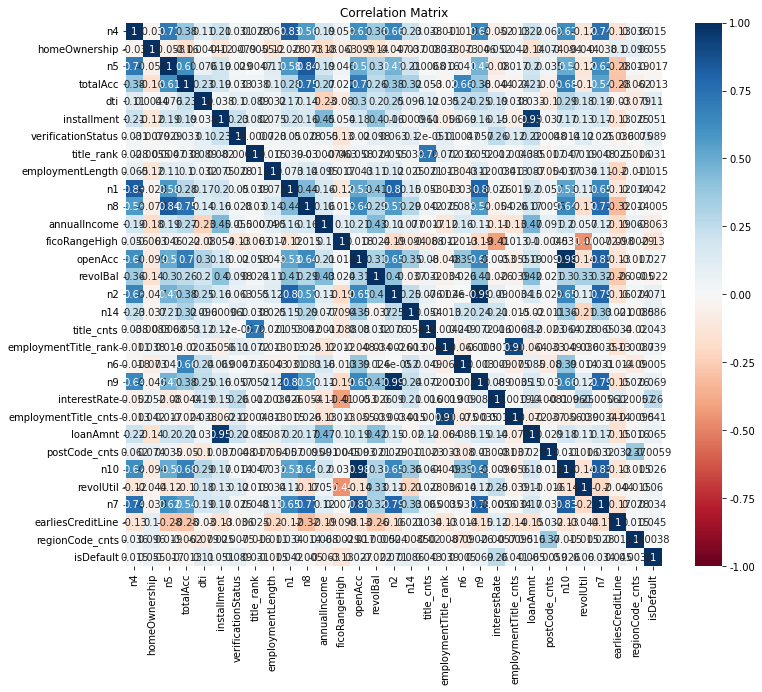

INFO - length of train:(552807, 33)
INFO - length of test:(236918, 33)
INFO - sample distribution:
INFO - 0    442246
1    110561
Name: isDefault, dtype: int64
INFO - model features persist success.
INFO - 剩余分类型变量个数：3
INFO - 剩余连续型变量个数：30
INFO - 剩余变量总数：33
INFO - persist custom_scaler success.
INFO - 剩余分类型变量个数：3
INFO - 剩余连续型变量个数：30
INFO - 剩余变量总数：33
INFO - 剩余分类型变量个数：3
INFO - 剩余连续型变量个数：30
INFO - 剩余变量总数：33
INFO - (552807, 56)
INFO - 剩余分类型变量个数：3
INFO - 剩余连续型变量个数：30
INFO - 剩余变量总数：33
INFO - (236918, 56)
INFO - 训练集特征维数：
INFO - (552807, 86)
INFO - 测试集特征维数：
INFO - (236918, 86)
INFO - model numbers:1
INFO - LightGBM模型 training
INFO - LightGBM模型保存成功！
INFO - LightGBM模型
INFO - model predict of train...
INFO - model eval of train...
INFO -                 AUC        KS      Lift  Accuracy  Precision    Recall  \
train_评估值  0.736843  0.344949  2.857427  0.806343   0.619822  0.082018   

                 F1      gini  
train_评估值  0.144867  0.473686  
INFO - roc curve of train...


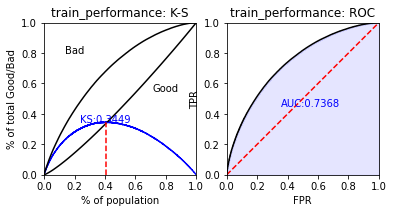

INFO - confusion matrix of train data...
INFO -               precision    recall  f1-score   support

           0       0.81      0.99      0.89    442246
           1       0.62      0.08      0.14    110561

    accuracy                           0.81    552807
   macro avg       0.72      0.53      0.52    552807
weighted avg       0.77      0.81      0.74    552807



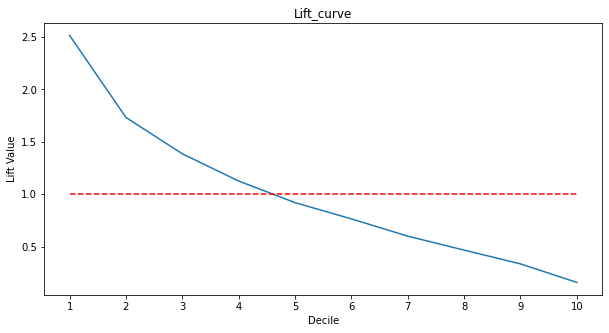

INFO - model report of train...
INFO - model distribution of train...
INFO - model score...
INFO - model predict of test...
INFO - model eval of test...
INFO -               AUC        KS      Lift  Accuracy  Precision    Recall  \
test_评估值  0.72243  0.322605  2.691626  0.804911    0.58225  0.086949   

                F1     gini  
test_评估值  0.151304  0.44486  
INFO - roc curve of test...


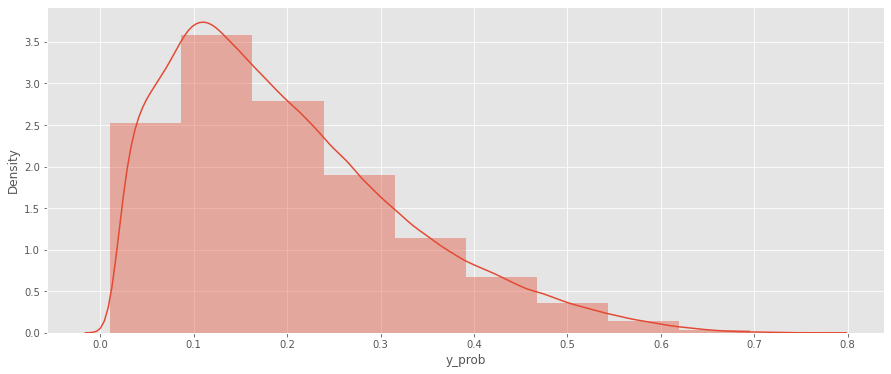

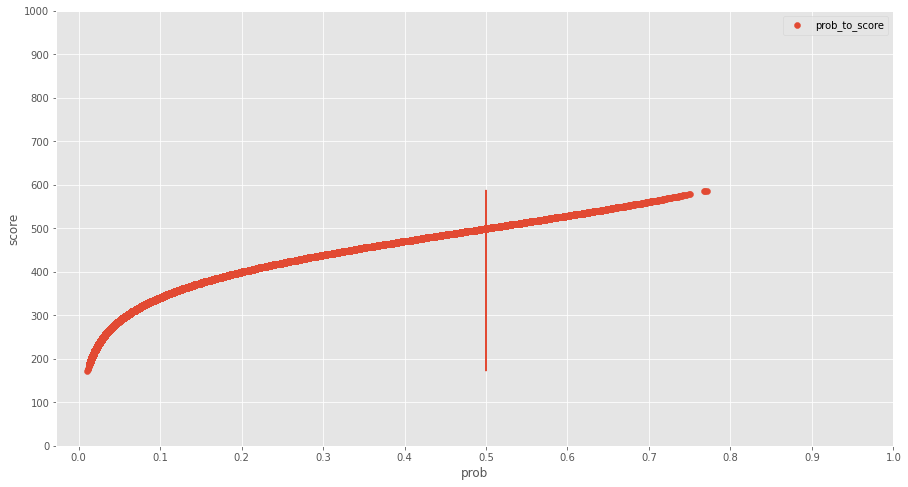

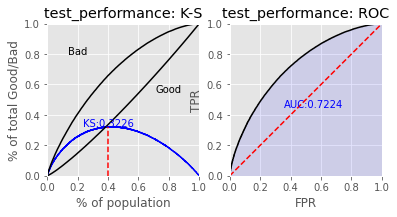

INFO - confusion matrix of test data...
INFO -               precision    recall  f1-score   support

           0       0.81      0.98      0.89    189534
           1       0.58      0.09      0.15     47384

    accuracy                           0.80    236918
   macro avg       0.70      0.54      0.52    236918
weighted avg       0.77      0.80      0.74    236918



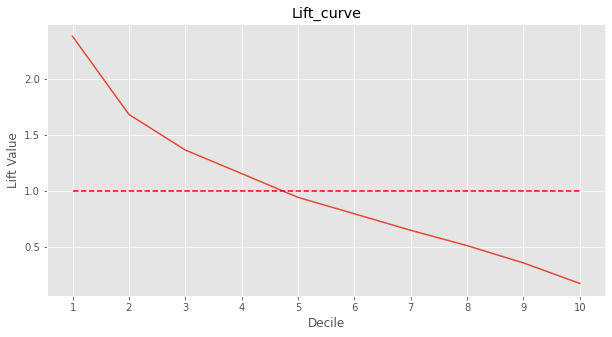

INFO - model report of test...
INFO - model distribution of test...
INFO - model score...
INFO - 训练测试模型PSI：nan


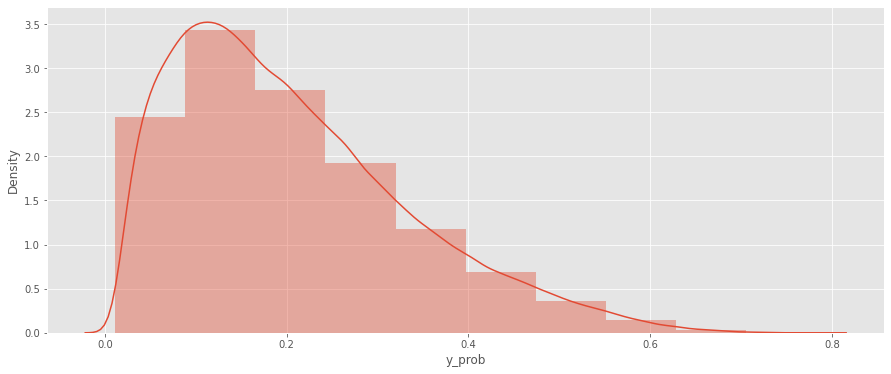

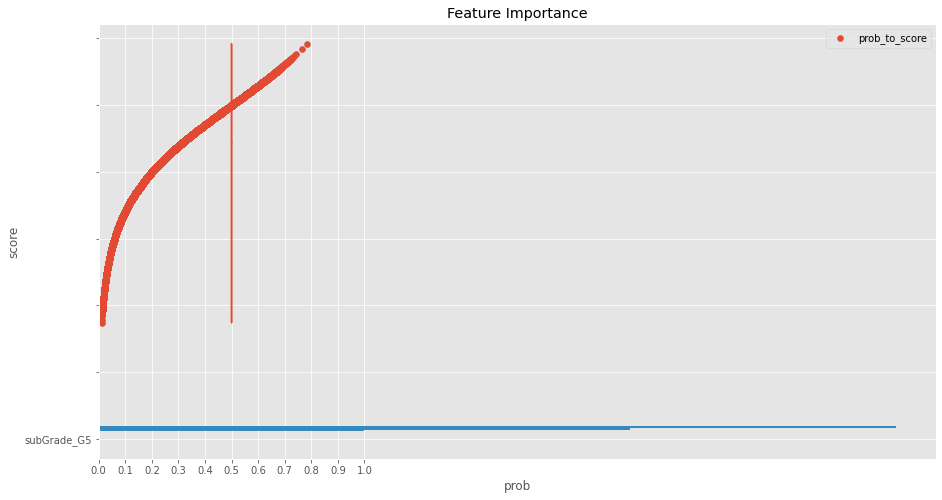

INFO - 输出特征重要性
INFO -                    index                 index  feature_importance        IV
0               loanAmnt              loanAmnt                 719  0.033026
1            installment           installment                 621  0.032620
2           interestRate          interestRate                 523  0.425274
3           annualIncome          annualIncome                 511  0.028351
4               revolBal              revolBal                 468  0.004166
5        regionCode_cnts       regionCode_cnts                 460  0.002252
6                    dti                   dti                 455  0.069831
7   employmentTitle_cnts  employmentTitle_cnts                 405  0.006867
8          ficoRangeHigh         ficoRangeHigh                 360  0.120009
9                     n2                    n2                 355  0.030309
10     earliesCreditLine     earliesCreditLine                 331  0.015316
11         postCode_cnts         postCode_cnts        

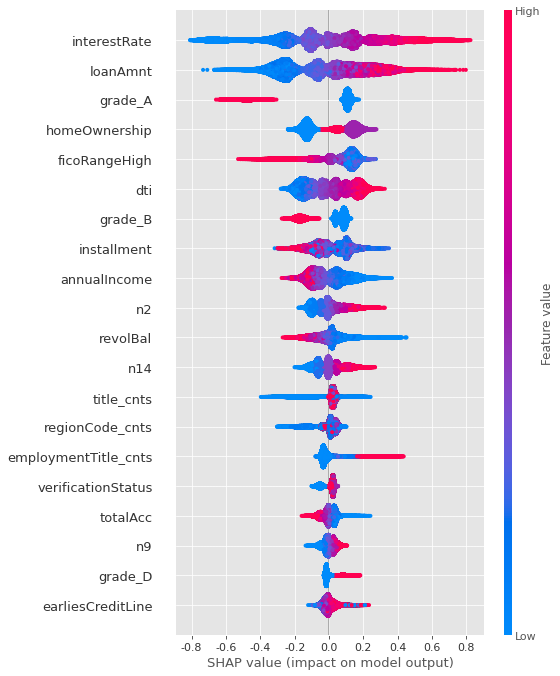

<Figure size 720x432 with 0 Axes>

In [3]:
mlModel.train(model_type='lgb')